# 03 LASSO回归 LASSO-Regression

## 1. 算法介绍



LASSO = 最小二乘回归 + L1正则化，可以把一些特征的回归系数直接压缩成 0，从而实现特征选择。

多个特征 \(X\) 时通常建议标准化，（x-均值）/方差

## 2. 数学原理



LASSO在普通最小二乘的基础上增加了：

$$ \lambda\sum_{j=1}^{p}|b_j| $$

p为特征个数。

因此 LASSO 的目标函数变成：

$$ \boxed{ J = \sum_{i=1}^{n} (y_i-a-\sum_{j=1}^{p}b_jx_{ij})^2 + \lambda\sum_{j=1}^{p}|b_j| } $$

$ \lambda $是正则化参数它决定我们到底有多在意“惩罚”。

λ比较小例如：$ \lambda=0.01 $惩罚比较弱。模型更加关注：把预测误差降低。

λ比较大例如：$ \lambda=10 $惩罚很强。模型会更加倾向于：让回归系数变小。甚至直接变成：$ b_j=0 $

我们期望：

$$  y_i-\beta_0-\beta_1x_{i1}-\beta_2x_{i2}-\beta_3x_{i3}\approx 0 $$

于是我们定义：

$$ r_i = y_i-\beta_0-\beta_1x_{i1}-\beta_2x_{i2} $$

这个 \(r_i\) 可以理解成：

在不考虑 \(X_3\) 的情况下，模型还剩下多少误差。

于是模型就变成：

$$ r_i\approx \beta_3x_{i3} $$

现在问题简单多了：

我应该找一个什么样的 β₃，让  $\beta_3x_{i3}$ 尽可能解释这些剩余误差？

我们先做一个普通最小二乘：

$$ \min_{\beta_3} \sum_i(r_i-\beta_3x_{i3})^2 $$

这句话就是：

找一个 β₃，让预测值

$$ \beta_3X_3 $$

尽可能接近剩余误差 r。

5. 对 β₃ 求导

把：

$$ J(\beta_3)=\sum_i(r_i-\beta_3x_{i3})^2 $$

对 β₃ 求导：

$$ \frac{dJ}{d\beta_3} = -2\sum_i x_{i3}(r_i-\beta_3x_{i3}) $$

为了让误差最小，导数必须等于 0：

$$ -2\sum_i x_{i3}(r_i-\beta_3x_{i3})=0 $$

把它展开：

$$ \sum_i x_{i3}r_i - \beta_3\sum_i x_{i3}^2 =0 $$

所以：

$$ \beta_3\sum_i x_{i3}^2 = \sum_i x_{i3}r_i $$

最终：

$$ \boxed{ \beta_3= \frac{\sum_i x_{i3}r_i} {\sum_i x_{i3}^2} } $$

加入惩罚项后分子为软阈值函数

$$ \boxed{ \rho=\sum X_jr } $$

可以理解成：当前这个 \(X_j\) 能够在多大程度上解释“剩余误差”。因为这个值越大，说明随着X3的改变对误差影响越大

## 3. 导入相关库

In [12]:
import numpy as np

## 4. 构造数据

In [13]:
np.random.seed(42)

n = 100
X = np.random.randn(n, 5)
Y = 3 * X[:, 0] + 2 * X[:, 1] - 4 * X[:, 2] + np.random.randn(n) * 0.5

## 5. 手动实现

In [14]:
X_mean = np.mean(X, axis=0)
X_std = np.std(X, axis=0)
X_standard  = (X - X_mean)/X_std

lambda_ = 0.1
b0 = np.mean(Y)
beta = np.zeros(X.shape[1])
epochs = 1000

def soft_thresholding(z, lambda_):
    if z > lambda_:
        return z - lambda_
    elif z < -lambda_:
        return z + lambda_
    else:
        return 0

for i in range(epochs):
    b0 = np.mean(Y - X_standard @ beta)
    for j in range(X.shape[1]):
        r = Y - b0 - X_standard @ beta + X_standard[:, j] * beta[j]
        rho = np.sum(X_standard[:, j] * r)
        beta[j] = soft_thresholding(rho, lambda_ * n) / np.sum(X_standard[:, j] ** 2)

print(b0)
for k in range(X.shape[1]):
    print(f"b{k+1}的系数等于", beta[k])
        

0.3375081525295168
b1的系数等于 2.5769832772219923
b2的系数等于 1.8902723970063966
b3的系数等于 -3.803428820513479
b4的系数等于 0.0
b5的系数等于 0.0


## 6. 使用 scikit-learn 库实现

In [15]:
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error

model = Lasso(alpha=0.1)

model.fit(X, Y)
Y_hat = model.predict(X)
print("截距 =", model.intercept_)
print("回归系数 =", model.coef_)

截距 = -0.04697793272600137
回归系数 = [ 2.86261744  1.9257929  -3.88163009  0.         -0.        ]


## 7. 可视化

c:\Users\Administrator\PythonProject\Statistics-Algorithms\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 39044 (\N{CJK UNIFIED IDEOGRAPH-9884}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\Administrator\PythonProject\Statistics-Algorithms\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 27979 (\N{CJK UNIFIED IDEOGRAPH-6D4B}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\Administrator\PythonProject\Statistics-Algorithms\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 20540 (\N{CJK UNIFIED IDEOGRAPH-503C}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\Administrator\PythonProject\Statistics-Algorithms\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 22238 (\N{CJK UNIFIED IDEOGRAPH-56DE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\U

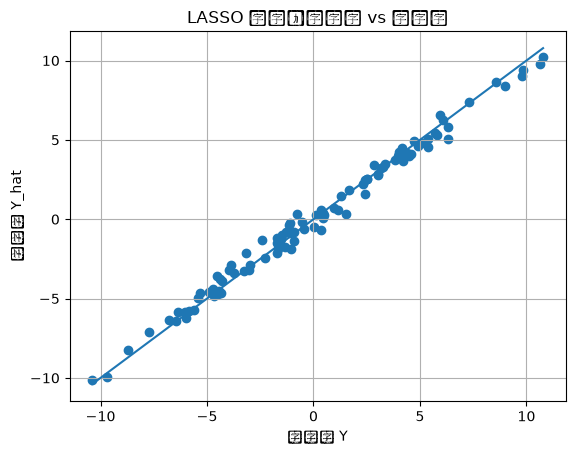

In [ ]:
import matplotlib.pyplot as plt

Y_hat = b0 + X_standard @ beta

plt.scatter(Y, Y_hat)
plt.plot([Y.min(), Y.max()],[Y.min(), Y.max()])
plt.xlabel("真实值 Y")
plt.ylabel("预测值 Y_hat")
plt.title("LASSO 回归：真实值 vs 预测值")
plt.show()

## 8.python新知识

1.np.random.seed(42)：随机种子，计算机是确定性机器，没有真正随机，相同 seed → 每次运行得到完全一样随机数

2.np.random.randn(d0, d1)：生成标准正态分布 N (0,1) 的数组，参数依次是行数、列数。np.random.normal(均值, 标准差, 生成数量)。random:随机，normal:正态分布。

3.X[:, 0] → 第 1 列，“:”表示所有行

4.axis=0 →按列计算，axis=1 → 按行计算

5.矩阵减向量，再除以向量成立，因为numpy的自动广播，可以把向量自动扩展成矩阵

6.X.shape:获取（行数，列数），X.shape[0]  → 行数。X.shape[1] → 列数

7.软阈值函数(Soft-Thresholding):绝对值小于lambda压缩为0，大于lambda向0收缩。

8.函数：def 函数名(参数1, 参数2):参数可以是之前定义过的实参，也可以是只占位的形参。函数结果用 return 返回

9.在求参数前先初始化该参数。

10.@ 是矩阵乘法运算符，若矩阵@一维数组，可以自动把一维数组视作列向量。

11.print(f"b{k+1}的系数等于", beta[k])。f:格式化字符串，{}内为数字，而非字符串。

12.x*y的值的大小可以用来判断x改变对y的影响程度

13.np.linspace(a, b, c):在a到b之间，均匀的生成c个数

14.plt.plot([1, 2, 3], [4, 5, 6])：基本语法：plt.plot(横坐标, 纵坐标)。原式表示得到三个点：(1, 4)(2, 5)(3, 6)然后把这些点连接起来。由于两点确定一条直线，所以知道两个点就可以作该直线的图。

15.要真实值接近预测值可视化：一个作横轴，一个作纵轴，看得到的散点图是否距离y=x很近